# Model input distributions -- Perera, Gesmundo, Ahneman

Every feature the GP actually receives, for the three benchmarks, read from each bundle's own
`inputs/config.json` rather than hand-listed -- so this stays correct if a bundle changes.

Two kinds of input, two kinds of plot:

| input | what it is | plot |
|---|---|---|
| **categorical** | the group (ligand / catalyst) plus `data.common_categorical` -- the reagents and conditions | stacked bar, one row per feature |
| **continuous** | the Kraken ligand descriptors each feature section uses, plus `data.common_numeric` | boxplot |

All three bundles have `common_numeric = []`, so they carry **no continuous reaction
conditions** -- no temperature, loading or residence time varies within these screens. Every
continuous input is therefore a ligand descriptor, and the target.

| dataset | group | categorical conditions | rows |
|---|---|---|---|
| Perera | `ligand` (8) | Reactant_1, Reagent_1, Solvent_1, substrate_pair | 3,072 |
| Gesmundo | `catalyst` (5) | base, cosolvent, core, monomer | 1,320 |
| Ahneman | `ligand` (4) | aryl_halide, base, additive | 3,955 |

In [4]:
import sys
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter, AutoMinorLocator

HUB = Path.cwd().parent / "gp_hub"
if not (HUB / "gpc").exists():
    HUB = Path.cwd() / "gp_hub"
sys.path.insert(0, str(HUB))

from gpc.config import SELECTED_SETS                      # noqa: E402
from gpc.data import load_bundle                          # noqa: E402
from gpc.features import model_columns                    # noqa: E402

DATASETS = ["perera", "gesmundo", "ahneman"]

bundles = {}
for name in DATASETS:
    reactions, ligands, reference, cfg = load_bundle(HUB / "datasets" / name / "inputs")
    bundles[name] = dict(reactions=reactions, ligands=ligands, reference=reference, cfg=cfg)
    data = cfg["data"]
    print(f"{name:10s} {len(reactions):5d} rows | group={data.get('group')!r} "
          f"({reactions[data.get('group')].nunique()}) | "
          f"target={data.get('target')!r} | common_numeric={data.get('common_numeric', [])}")

perera      3072 rows | group='ligand' (8) | target='Product_Yield_PCT_Area_UV' | common_numeric=[]
gesmundo    1320 rows | group='catalyst' (5) | target='conversion' | common_numeric=[]
ahneman     3955 rows | group='ligand' (4) | target='yield' | common_numeric=[]


## Which columns reach the model

`model_columns` is the same function the training pipeline calls, so this table is the真
definition of the inputs, not a restatement of it. The union across every feature section the
bundle declares is what the plots below cover.

In [5]:
rows = []
for name, b in bundles.items():
    cfg, reference = b["cfg"], b["reference"]
    for model in cfg["features"]["models"]:
        num, cat = model_columns(model, cfg, reference)
        rows.append({"dataset": name, "section": model,
                     "n_numeric": len(num), "n_categorical": len(cat),
                     "numeric": ", ".join(num) if len(num) <= 6 else f"{len(num)} descriptors"})
sections = pd.DataFrame(rows)
print(sections.to_string(index=False))

 dataset         section  n_numeric  n_categorical                                                                            numeric
  perera       group_ohe          0              5                                                                                   
  perera      selected_2          2              4                                                       vbur_pct_boltz, vbur_pct_min
  perera   vbur_min_vmin          2              4                                                      vbur_pct_min, vmin_vmin_boltz
  perera vbur_boltz_vmin          2              4                                                    vbur_pct_boltz, vmin_vmin_boltz
  perera      selected_5          5              4 vbur_pct_boltz, vbur_pct_min, vbur_pct_delta, dipolemoment_boltz, homo_lumo_gap_eV
  perera          pc_top         12              4                                                                     12 descriptors
  perera       pc_scores          4              4            

In [6]:
# Union of inputs per dataset: categorical, and continuous
inputs = {}
for name, b in bundles.items():
    cfg, reference = b["cfg"], b["reference"]
    cats, nums = [], []
    for model in cfg["features"]["models"]:
        num, cat = model_columns(model, cfg, reference)
        for c in cat:
            if c not in cats:
                cats.append(c)
        for c in num:
            if c not in nums:
                nums.append(c)
    inputs[name] = {"categorical": cats, "continuous": nums,
                    "target": cfg["data"]["target"], "group": cfg["data"].get("group")}
    print(f"=== {name} ===")
    print(f"  categorical ({len(cats)}): {cats}")
    print(f"  continuous  ({len(nums)}): {nums if len(nums) <= 8 else nums[:6] + ['...']}")
    print(f"  target: {inputs[name]['target']}\n")

=== perera ===
  categorical (5): ['ligand', 'Reactant_1_Short_Hand', 'Reagent_1_Short_Hand', 'Solvent_1_Short_Hand', 'substrate_pair']
  continuous  (22): ['vbur_pct_boltz', 'vbur_pct_min', 'vmin_vmin_boltz', 'vbur_pct_delta', 'dipolemoment_boltz', 'homo_lumo_gap_eV', '...']
  target: Product_Yield_PCT_Area_UV

=== gesmundo ===
  categorical (5): ['catalyst', 'base', 'cosolvent', 'core', 'monomer']
  continuous  (22): ['vbur_pct_boltz', 'vbur_pct_min', 'vmin_vmin_boltz', 'vbur_pct_delta', 'dipolemoment_boltz', 'homo_lumo_gap_eV', '...']
  target: conversion

=== ahneman ===
  categorical (4): ['ligand', 'aryl_halide', 'base', 'additive']
  continuous  (22): ['vbur_pct_boltz', 'vbur_pct_min', 'vmin_vmin_boltz', 'vbur_pct_delta', 'dipolemoment_boltz', 'homo_lumo_gap_eV', '...']
  target: yield



## 1. Categorical inputs

One stacked bar per feature, segments sized by how many reactions use each level. Labels fit
to their segment: name over count where there is room, name beside count rotated when that
renders larger, name alone, then the count alone. The pooled segment never truncates -- its
`(#)` is the point of it.

In [ ]:
# Chemical role of each model input, per dataset. The y-tick label shows the
# role on top (only when it differs from the column name), the column name as
# the bundle calls it in the middle, and the level count at the bottom.
FEATURE_ROLE = {
    "perera": {
        "ligand":                "Ligand",
        "Reactant_1_Short_Hand": "Halide",            # 6-Cl/Br/OTf/I-quinoline
        "Reagent_1_Short_Hand":  "Base",              # CsF, K3PO4, Et3N, ...
        "Solvent_1_Short_Hand":  "Solvent",
        "substrate_pair":        "Halide x boron source",   # 4 halides x 3 boron sources
    },
    "gesmundo": {
        "catalyst":  "Ligand (precatalyst)",
        "base":      "Base",
        "cosolvent": "Cosolvent",
        "core":      "Halide (scaffold)",             # the aryl halide being functionalised
        "monomer":   "Boronic acid",                  # MFCD catalogue numbers
    },
    "ahneman": {
        "ligand":      "Ligand",
        "aryl_halide": "Halide",
        "base":        "Base",
        "additive":    "Additive (isoxazole)",
        # Buchwald-Hartwig: no boron partner, and the amine is fixed across the screen
    },
}


def tick_label(feature, n_levels, roles):
    """Role on top when it adds something, then the column name, then the count."""
    role = roles.get(feature)
    plain = feature.replace("_", " ").lower()
    lines = []
    if role and role.lower() != plain:
        lines.append(role)
    lines += [feature, f"({n_levels})"]
    return chr(10).join(lines)


FONT_SIZE = 15
NAME_MIN_SIZE = 8
FIGURE_WIDTH = 20     # fixed across datasets: a wider figure scaled to the same
                      # page width renders its text smaller, so equal apparent
                      # label size means equal figure width
ROW_HEIGHT = 2.1      # inches per feature, fixed, so bars are the same height
                      # in every figure regardless of how many levels a row has


def all_categories(series):
    """Every level, largest first. Nothing is pooled: two categories of similar
    size must stay separate, so there is no 'Other' bucket."""
    return series.value_counts(dropna=False)


def _clip(name, n):
    return name if len(name) <= n else name[:n - 1] + "\u2026"


def _wrap(name, width):
    lines = textwrap.wrap(name, width) or [name]
    if len(lines) > 3:
        lines = lines[:3]
        lines[-1] = lines[-1][:-1] + "\u2026"
    return lines


def name_count_texts(name, count, rotation):
    """Name AND count, most complete first, for one orientation."""
    count_s = f"{count:,}"
    if rotation == 0:
        return ["\n".join(_wrap(name, w) + [count_s])
                for w in (len(name), 30, 24, 18, 14, 10)]
    # rotated: inline, so the number sits beside the name rather than after it
    return [f"{_clip(name, n)}  {count_s}" for n in (len(name), 26, 20, 15, 11, 7)]


def name_only_texts(name, rotation):
    widths = (len(name), 22, 16, 11) if rotation == 0 else (len(name), 26, 20, 15, 11, 7, 4)
    return [_clip(name, n) for n in widths]


def _first_fitting(text, rect, candidates, rotation, size, renderer):
    """The most complete candidate that fits this segment, or None."""
    box = rect.get_window_extent(renderer)
    text.set_fontsize(size)
    text.set_rotation(rotation)
    for candidate in candidates:
        text.set_text(candidate)
        ext = text.get_window_extent(renderer)
        if ext.width <= box.width - 3 and ext.height <= box.height - 3:
            return candidate
    return None


def _shown(label, name):
    """Fraction of `name` the label actually spells out."""
    body = label.replace("\u2026", "")
    kept = sum(1 for ch in name if ch in body)
    return kept / max(len(name), 1)


def layout_row(row_segments, renderer):
    """One rotation and one font size for the whole row.

    Chosen by how much of the NAME survives, not by font size: rotating buys a
    bigger font but forces single-line truncation, and a readable name at 13pt
    beats "1-chlo..." at 15pt. Font size breaks ties, then horizontal breaks
    those -- so a row only turns vertical when that genuinely shows more text,
    which in practice means the very thin rows.

    Orientation is decided once per row, so a row never mixes the two.
    """
    best = None
    for mode in ("name_count", "name_only"):
        for size in range(FONT_SIZE, NAME_MIN_SIZE - 1, -1):
            for rotation in (0, 90):
                chosen, worst = [], 1.0
                for rect, text, name, count in row_segments:
                    cands = (name_count_texts(name, count, rotation) if mode == "name_count"
                             else name_only_texts(name, rotation))
                    hit = _first_fitting(text, rect, cands, rotation, size, renderer)
                    if hit is None:
                        break
                    chosen.append(hit)
                    worst = min(worst, _shown(hit, name))
                else:
                    key = (round(worst, 3), size, rotation == 0)
                    if best is None or key > best[0]:
                        best = (key, rotation, size, chosen, mode)
            if best is not None and best[0][0] >= 0.999:
                break      # every name complete at this size; no need to shrink
        if best is not None:
            break          # name_count worked; never fall back to name_only
    if best is not None:
        _, rotation, size, chosen, mode = best
        return rotation, size, chosen, mode

    for size in range(FONT_SIZE, NAME_MIN_SIZE - 1, -1):
        for rotation in (0, 90):
            chosen = []
            for rect, text, name, count in row_segments:
                hit = _first_fitting(text, rect, [f"{count:,}"], rotation, size, renderer)
                if hit is None:
                    break
                chosen.append(hit)
            else:
                return rotation, size, chosen, "count_only"
    return 0, NAME_MIN_SIZE, [""] * len(row_segments), "blank"


def distribution_figure(frame, features, title, roles=None, width=FIGURE_WIDTH):
    features = [c for c in features if c in frame.columns and frame[c].notna().any()]
    total = len(frame)
    colors = plt.get_cmap("tab20").colors

    fig, ax = plt.subplots(figsize=(width, ROW_HEIGHT * len(features) + 1))
    rows = []
    for row, feature in enumerate(features):
        left = 0
        segs = []
        for i, (value, count) in enumerate(all_categories(frame[feature]).items()):
            name = "NA" if pd.isna(value) else str(value)
            rect = ax.barh(row, count, left=left, height=0.85,
                           color=colors[i % len(colors)],
                           edgecolor="white", linewidth=1)[0]
            text = ax.text(left + count / 2, row, "", ha="center", va="center",
                           fontsize=FONT_SIZE, rotation_mode="anchor")
            segs.append((rect, text, name, count))
            left += count
        rows.append((feature, segs))

    roles = roles or {}
    labels = [tick_label(c, frame[c].nunique(dropna=False), roles)
              for c in features]
    ax.set_yticks(range(len(features)), labels=labels, fontsize=13)
    ax.set_ylim(len(features) - 0.5, -0.5)
    ax.set_xlim(0, total)
    ax.set_xlabel("Number of reactions", fontsize=15)
    ax.set_title(f"{title}  (n = {total:,})", fontsize=17, pad=12)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(axis="x", which="both", direction="in", labelsize=12)
    ax.tick_params(axis="y", length=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

    fig.tight_layout()
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for feature, segs in rows:
        rotation, size, chosen, mode = layout_row(segs, renderer)
        for (rect, text, name, count), label in zip(segs, chosen):
            text.set_rotation(rotation)
            text.set_fontsize(size)
            text.set_text(label)
    return fig


In [ ]:
plt.close("all")
for name, b in bundles.items():
    features = inputs[name]["categorical"]
    fig = distribution_figure(b["reactions"], features, name.capitalize(),
                              roles=FEATURE_ROLE.get(name, {}))
    display(fig)
    plt.close(fig)

## 2. Continuous inputs -- ligand descriptors

Every continuous column any feature section feeds the GP. They are properties of the *ligand*,
so each takes only as many distinct values as the screen has ligands (8 / 5 / 4) -- the
boxplot is over reactions, so a ligand used twice as often pulls twice as hard. That is what
the model sees, which is the point, but it means these are not smooth distributions.

Raw units differ (percent, Debye, eV, PC score), so the first figure standardises each
descriptor against the **full 1,223-ligand Kraken population**. A box sitting away from 0 says
the screen picked ligands unusual for that property; a narrow box says the screen barely
varied it.

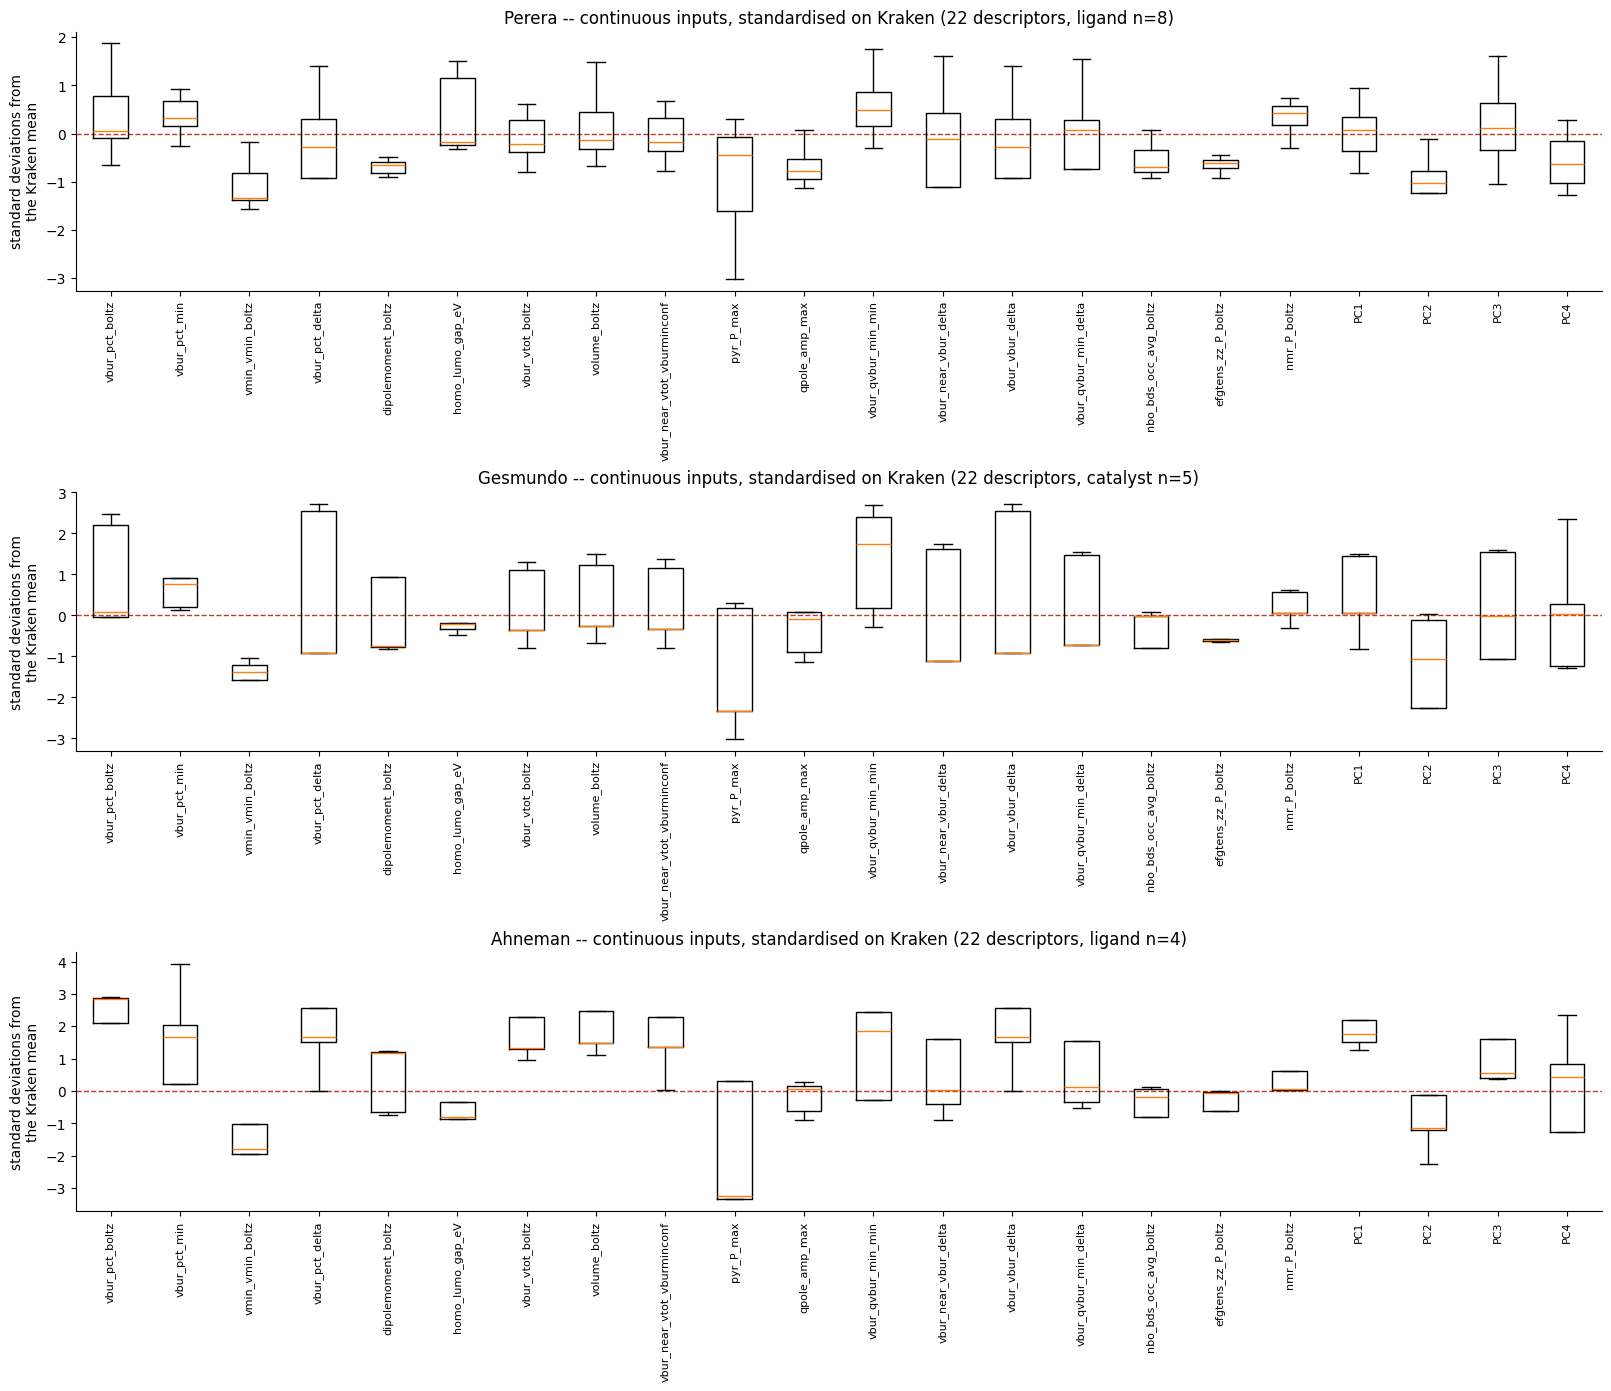

In [6]:
kraken_pop = pd.read_csv(HUB / "reference" / "kraken" / "ligand_features.csv")

def descriptor_frame(name, standardise=True):
    """One row per reaction, one column per continuous model input."""
    b = bundles[name]
    cols = [c for c in inputs[name]["continuous"] if c in b["ligands"].columns]
    merged = b["reactions"][["kraken_id"]].merge(
        b["ligands"][["kraken_id", *cols]], on="kraken_id", how="left")
    values = merged[cols].apply(pd.to_numeric, errors="coerce")
    if standardise:
        ref = kraken_pop[cols].apply(pd.to_numeric, errors="coerce")
        values = (values - ref.mean()) / ref.std(ddof=0).replace(0, 1)
    return values


plt.close("all")
fig, axes = plt.subplots(len(DATASETS), 1, figsize=(16, 4.6 * len(DATASETS)),
                         constrained_layout=True)
for ax, name in zip(np.atleast_1d(axes), DATASETS):
    z = descriptor_frame(name, standardise=True)
    ax.boxplot([z[c].dropna() for c in z.columns], tick_labels=list(z.columns),
               showfliers=False)
    ax.axhline(0, color="#c0392b", lw=1, ls="--", zorder=0)
    ax.set(title=f"{name.capitalize()} -- continuous inputs, standardised on Kraken "
                 f"({len(z.columns)} descriptors, {inputs[name]['group']} "
                 f"n={bundles[name]['reactions'][inputs[name]['group']].nunique()})",
           ylabel="standard deviations from\nthe Kraken mean")
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
display(fig)
plt.close(fig)

### The same descriptors in their own units

Standardising makes the panels comparable but hides the real values. These are the raw
numbers, one small boxplot per descriptor, so the physical range is visible.

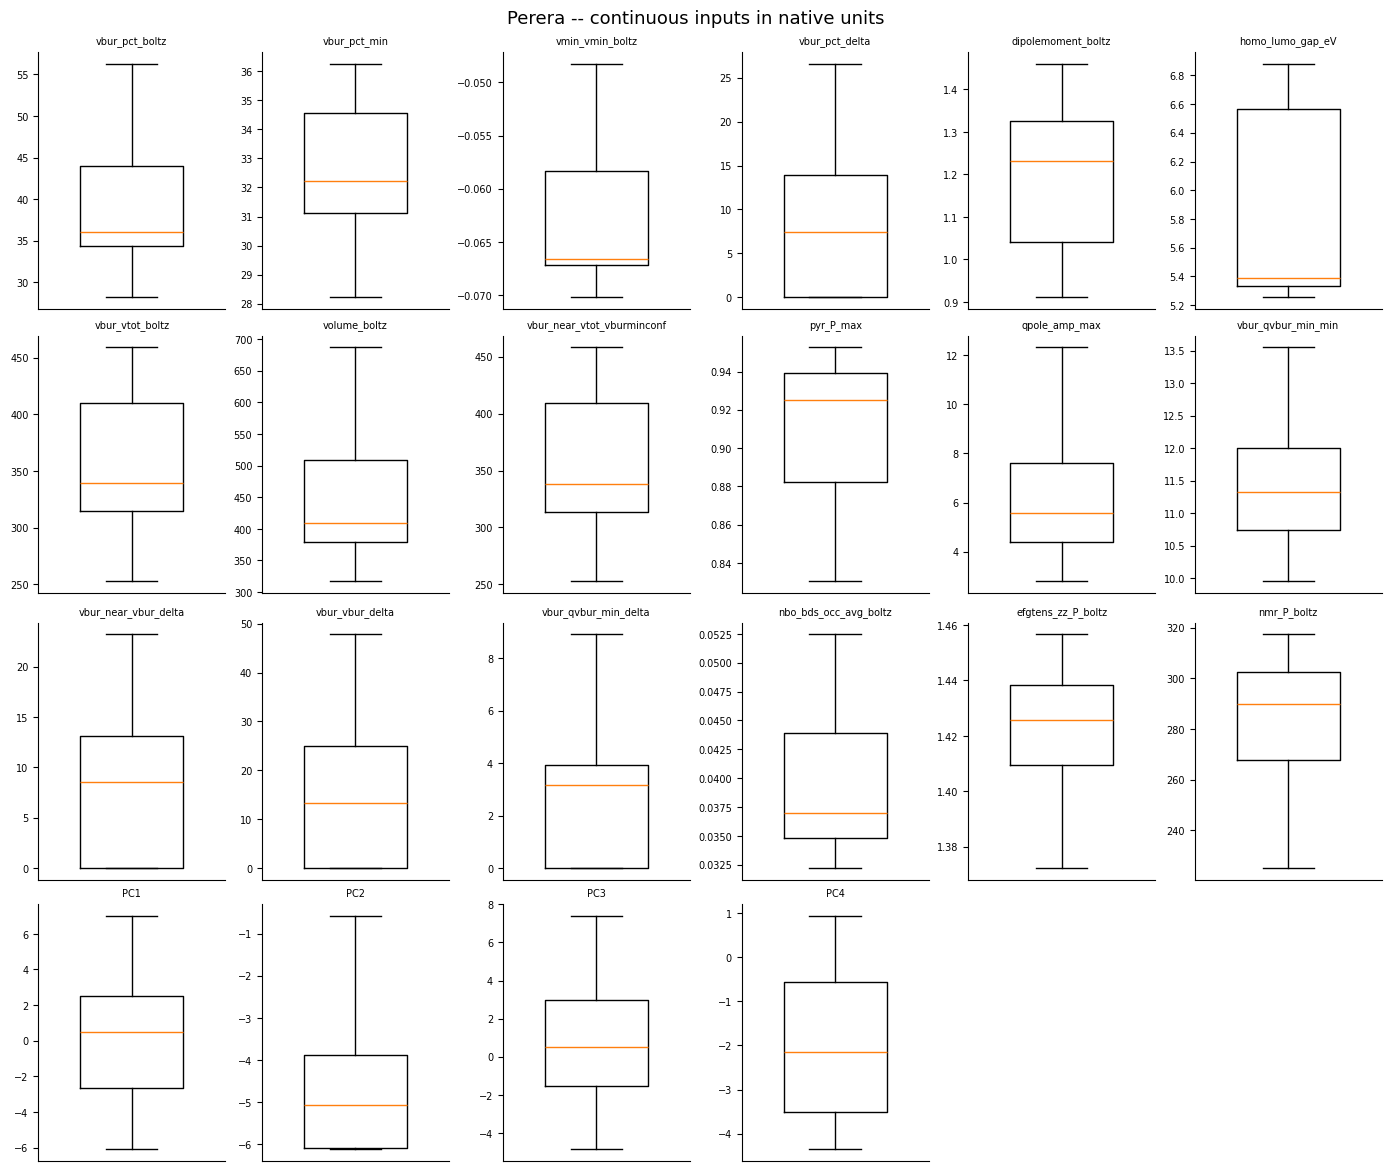

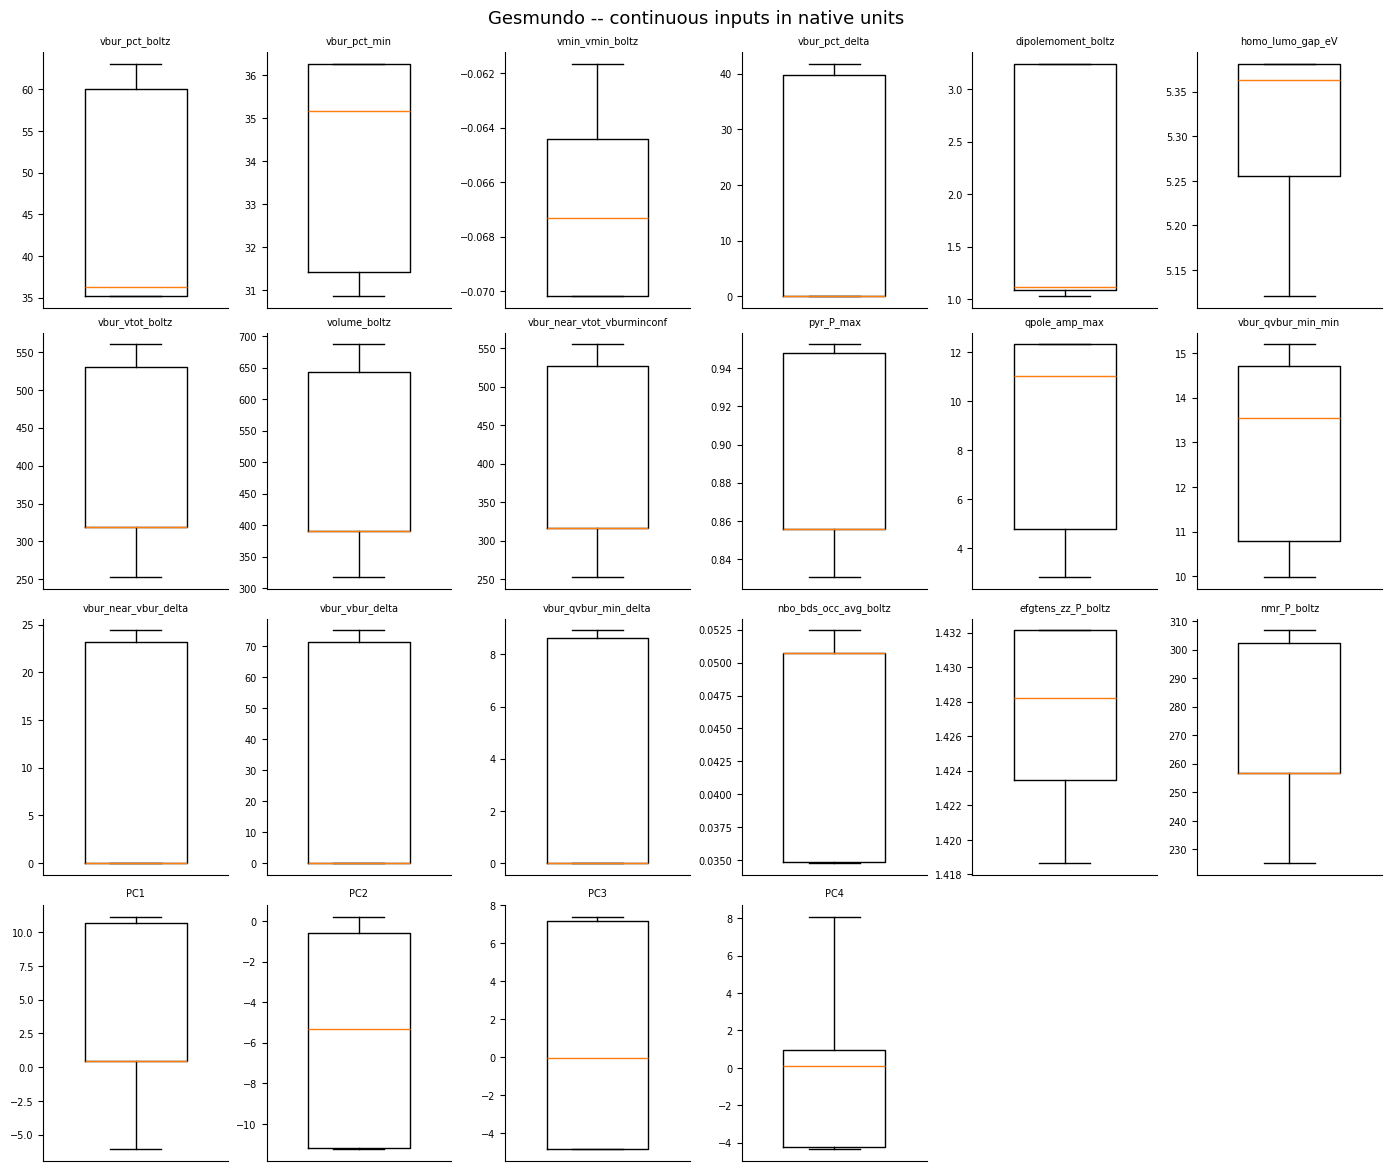

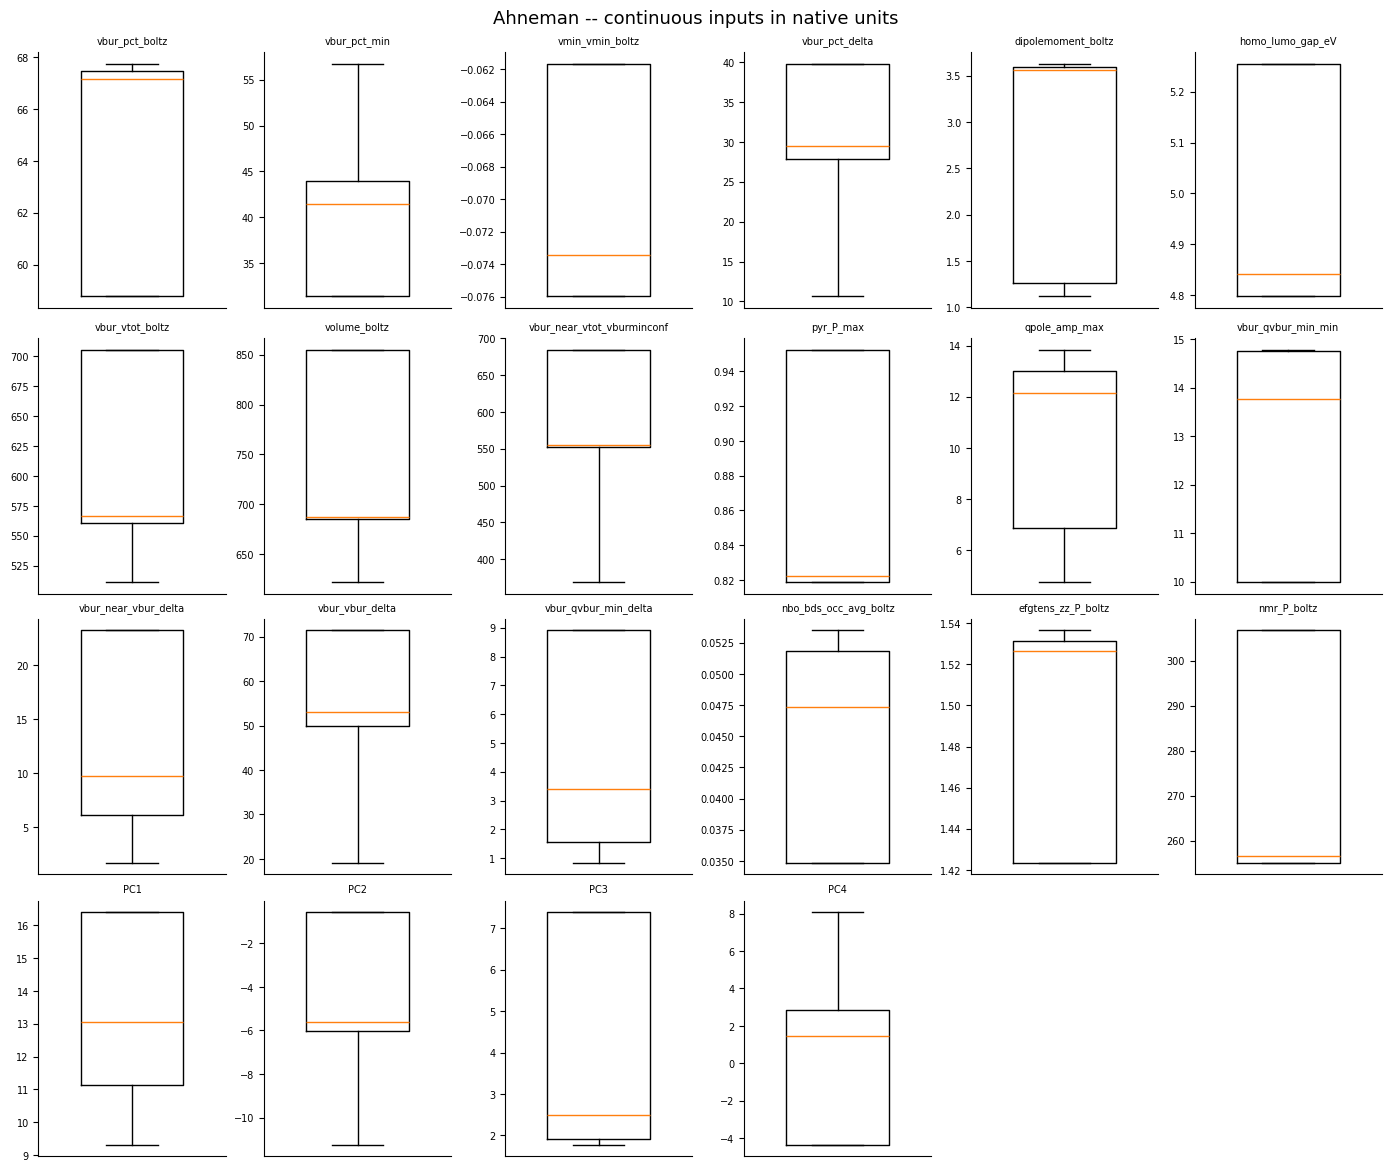

In [7]:
plt.close("all")
for name in DATASETS:
    raw = descriptor_frame(name, standardise=False)
    cols = list(raw.columns)
    ncol = min(6, len(cols))
    nrow = int(np.ceil(len(cols) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.3 * ncol, 2.9 * nrow),
                             constrained_layout=True)
    flat = np.atleast_1d(axes).ravel()
    for ax, c in zip(flat, cols):
        ax.boxplot(raw[c].dropna(), showfliers=False, widths=0.55)
        ax.set_title(c, fontsize=7)
        ax.set_xticks([])
        ax.tick_params(axis="y", labelsize=7)
        ax.spines[["top", "right"]].set_visible(False)
    for ax in flat[len(cols):]:
        ax.set_visible(False)
    fig.suptitle(f"{name.capitalize()} -- continuous inputs in native units", fontsize=13)
    display(fig)
    plt.close(fig)

### Per-descriptor spread by ligand

Because the descriptors are constant within a ligand, the useful question is how much they
separate the ligands the screen actually used. A descriptor whose ligand values nearly
coincide gives the GP almost nothing to work with on that axis.

In [8]:
rows = []
for name in DATASETS:
    b = bundles[name]
    group = inputs[name]["group"]
    cols = [c for c in inputs[name]["continuous"] if c in b["ligands"].columns]
    per_ligand = (b["reactions"][[group, "kraken_id"]].drop_duplicates()
                  .merge(b["ligands"][["kraken_id", *cols]], on="kraken_id", how="left"))
    ref = kraken_pop[cols].apply(pd.to_numeric, errors="coerce")
    for c in cols:
        v = pd.to_numeric(per_ligand[c], errors="coerce")
        sd = ref[c].std(ddof=0)
        rows.append({"dataset": name, "descriptor": c, "n_ligands": v.notna().sum(),
                     "min": v.min(), "max": v.max(),
                     "spread_in_kraken_sd": (v.max() - v.min()) / sd if sd else np.nan})
spread = pd.DataFrame(rows)
print("range the screen covers, in Kraken standard deviations "
      "(small = the screen barely varied this descriptor)\n")
for name in DATASETS:
    sub = spread[spread.dataset == name].sort_values("spread_in_kraken_sd")
    print(f"=== {name} ===")
    print(sub[["descriptor", "n_ligands", "min", "max", "spread_in_kraken_sd"]]
          .round(3).to_string(index=False), "\n")

range the screen covers, in Kraken standard deviations (small = the screen barely varied this descriptor)

=== perera ===
                descriptor  n_ligands     min     max  spread_in_kraken_sd
        efgtens_zz_P_boltz          8   1.372   1.457                0.472
     nbo_bds_occ_avg_boltz          8   0.032   0.052                1.005
               nmr_P_boltz          8 225.189 317.294                1.046
              vbur_pct_min          8  28.224  36.264                1.180
             qpole_amp_max          8   2.815  12.312                1.214
                       PC4          8  -4.352   0.931                1.546
           vmin_vmin_boltz          8  -0.070  -0.043                1.709
          homo_lumo_gap_eV          8   5.255   6.881                1.836
           vbur_vtot_boltz          8 253.200 560.364                2.107
                       PC2          8 -11.179  -0.575                2.133
vbur_near_vtot_vburminconf          8 253.200 555.129

## 3. The target

Continuous, so a boxplot -- overall and split by the group the LOLO folds hold out, since that
split is what the benchmark is built around.

perera     n= 3072  min=   0.00  median=  46.81  mean=  47.64  max= 100.00
gesmundo   n= 1320  min=   0.00  median=  24.09  mean=  40.16  max= 100.00
ahneman    n= 3955  min=   0.00  median=  28.76  mean=  33.09  max= 100.00


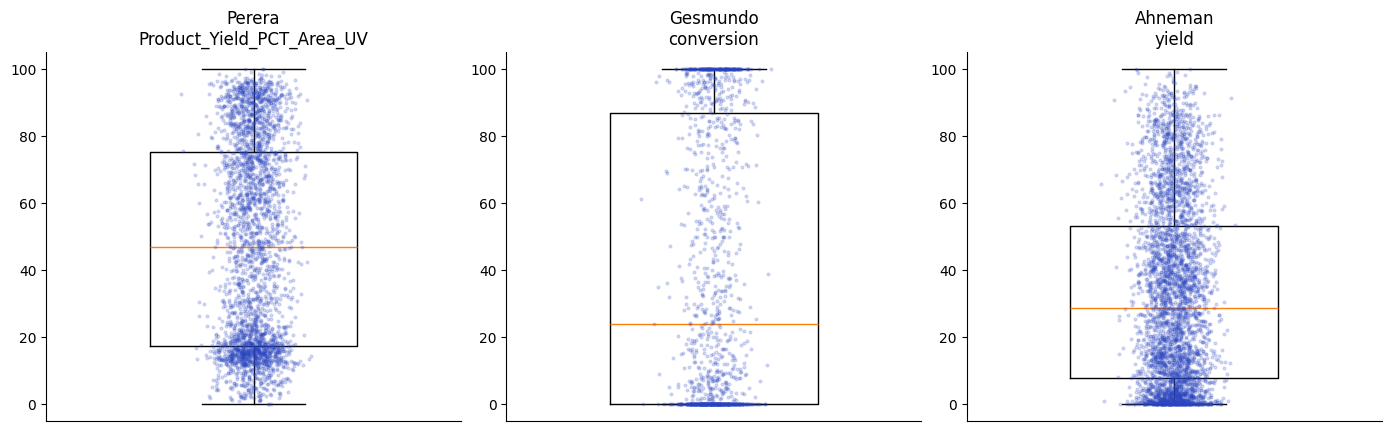

In [10]:
plt.close("all")
fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.6 * len(DATASETS), 4.2),
                         constrained_layout=True)
for ax, name in zip(np.atleast_1d(axes), DATASETS):
    b = bundles[name]
    y = pd.to_numeric(b["reactions"][inputs[name]["target"]], errors="coerce").dropna()
    ax.boxplot(y, showfliers=False, widths=0.5)
    ax.scatter(np.random.default_rng(0).normal(1, 0.045, len(y)), y,
               s=4, alpha=0.18, color="#2b46c0", zorder=3)
    ax.set(title=f"{name.capitalize()}\n{inputs[name]['target']}", xticks=[])
    ax.spines[["top", "right"]].set_visible(False)
    print(f"{name:10s} n={len(y):5d}  min={y.min():7.2f}  median={y.median():7.2f}  "
          f"mean={y.mean():7.2f}  max={y.max():7.2f}")
display(fig)
plt.close(fig)

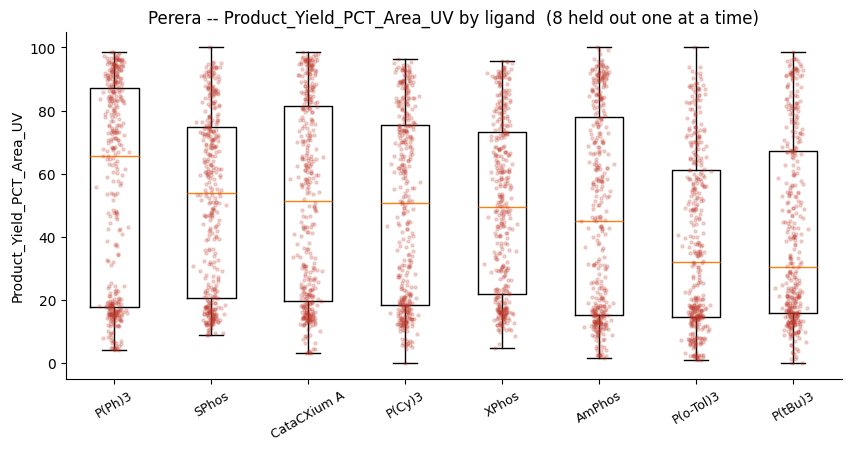

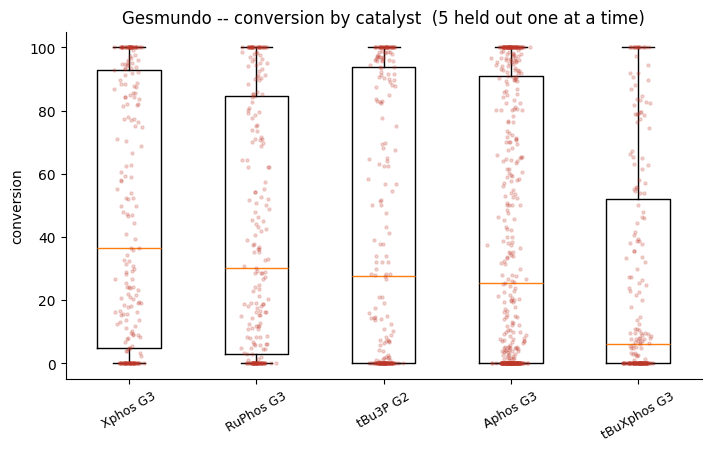

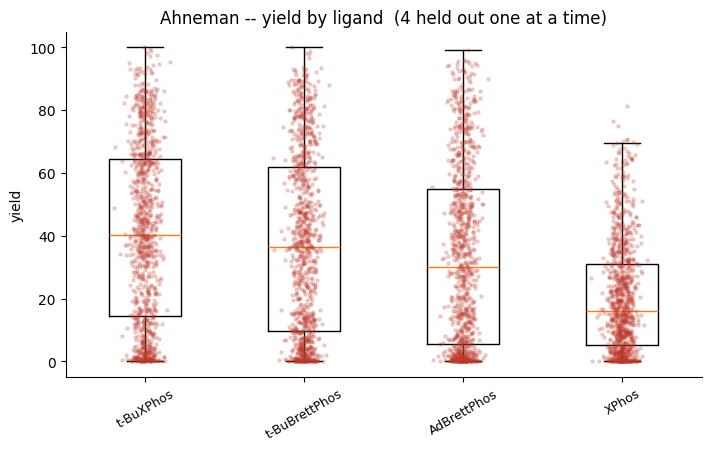

In [11]:
plt.close("all")
for name in DATASETS:
    b = bundles[name]
    group, target = inputs[name]["group"], inputs[name]["target"]
    frame = b["reactions"][[group, target]].copy()
    frame[target] = pd.to_numeric(frame[target], errors="coerce")
    order = frame.groupby(group)[target].median().sort_values(ascending=False).index.tolist()
    data = [frame.loc[frame[group] == g, target].dropna().values for g in order]
    fig, ax = plt.subplots(figsize=(max(7, 1.05 * len(order)), 4.4), constrained_layout=True)
    ax.boxplot(data, tick_labels=order, showfliers=False)
    for i, values in enumerate(data, start=1):
        ax.scatter(np.random.default_rng(0).normal(i, 0.05, len(values)), values,
                   s=5, alpha=0.2, color="#c0392b", zorder=3)
    ax.set(title=f"{name.capitalize()} -- {target} by {group}  ({len(order)} held out one at a time)",
           ylabel=target)
    ax.tick_params(axis="x", rotation=30, labelsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    display(fig)
    plt.close(fig)